# Single-Stock Risk Report

A parameterized report for one stock over one date range, built from the cleaned `ohlc_hw_cleaned` table
(see `01_data_cleaning.ipynb`). Run it interactively, or let `03_run_all_stocks.py` execute it with
papermill for every ticker.

Returns and drawdowns use **adjusted closes**, so splits and dividends don't show up as fake moves. Volatility,
the Sharpe ratio and all daily-return statistics use **daily log returns**.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

%matplotlib inline

## Parameters

The next cell is tagged `parameters`. Papermill injects a new cell right after it that overrides these
defaults.

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # SQLite database containing ohlc_hw_cleaned
risk_free_rate = 0.02  # Annual risk-free rate used in the Sharpe ratio

In [3]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


In [4]:
TRADING_DAYS = 252   # trading days per year, used to annualize
VOL_WINDOW = 20      # rolling volatility window (returns)
MA_WINDOW = 50       # moving average window (prices)

# One colour scheme for every chart
GREEN, RED, GREY = "#2e7d32", "#c62828", "#9e9e9e"
NAVY, PURPLE, DARK_RED = "#1a237e", "#6a1b9a", "#8e0000"

plt.style.use("seaborn-v0_8-whitegrid")


def fmt(value, spec: str) -> str:
    """Format a number for display, or 'N/A' if it is undefined (NaN)."""
    return "N/A" if pd.isna(value) else format(value, spec)

## Data loading

In [5]:
def load_prices(ticker: str, start_date: str, end_date: str, db_path: str) -> pd.DataFrame:
    """Load cleaned daily data for one ticker between start_date and end_date (inclusive), indexed by date."""
    database = Path(db_path)
    if not database.is_file():
        raise FileNotFoundError(f"Database not found: {database.resolve()}")
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start > end:
        raise ValueError(f"start_date {start_date} is after end_date {end_date}")

    query = """
        SELECT ts, open, high, low, close, adj_close, volume,
               flag_adj_repaired, flag_close_repaired, flag_open_repaired, flag_return_outlier
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts BETWEEN ? AND ?
        ORDER BY ts
    """
    # open read-only, so a report can never modify the database
    with closing(sqlite3.connect(f"{database.resolve().as_uri()}?mode=ro", uri=True)) as conn:
        return pd.read_sql_query(query, conn, params=(ticker, f"{start:%Y-%m-%d}", f"{end:%Y-%m-%d}"),
                                 parse_dates=["ts"], index_col="ts")


prices = load_prices(ticker, start_date, end_date, db_path)

if len(prices) < VOL_WINDOW + 1:
    raise ValueError(f"{ticker}: only {len(prices)} prices between {start_date} and {end_date}; "
                     f"at least {VOL_WINDOW + 1} are needed for {VOL_WINDOW} returns")

first_day, last_day = prices.index[0], prices.index[-1]
print(f"{ticker} from {start_date} to {end_date}: {len(prices)} trading days")
print(f"Actual observations: {first_day:%Y-%m-%d} to {last_day:%Y-%m-%d}")
if last_day < pd.Timestamp(end_date) - pd.offsets.BDay(5):
    print(f"Note: {ticker}'s data ends on {last_day:%Y-%m-%d}, before the requested end date {end_date}. "
          "Prices are not extrapolated, so this report covers a shorter period.")

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual observations: 2024-06-03 to 2024-11-29


In [6]:
display(prices.head())
display(prices.tail())

,open,high,low,close,adj_close,volume,flag_adj_repaired,flag_close_repaired,flag_open_repaired,flag_return_outlier
ts,,,,,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100,0,0,0,0
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203,0,0,0,0
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400,0,0,0,0
2024-06-06,167.38,168.44,166.80,168.20,165.44,2207263,0,0,0,0
2024-06-07,168.18,171.31,168.06,170.01,167.22,3475500,0,0,0,0


,open,high,low,close,adj_close,volume,flag_adj_repaired,flag_close_repaired,flag_open_repaired,flag_return_outlier
ts,,,,,,,,,,
2024-11-22,223.35,227.20,220.89,222.97,222.97,5320740,0,0,0,0
2024-11-25,223.35,226.42,222.65,226.13,226.13,7189300,0,0,0,0
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543,0,0,0,0
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121,0,0,0,0
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300,0,0,0,0


In [7]:
# Rows in this window that were repaired or flagged during cleaning (see 01_data_cleaning.ipynb)
prices.filter(like="flag_").sum().rename("rows in window").to_frame()

,rows in window
flag_adj_repaired,8
flag_close_repaired,0
flag_open_repaired,0
flag_return_outlier,1


## Risk metrics

In [8]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns: ln(P_t / P_{t-1}). The first value is NaN.

    Log returns add up over time, so the sum of daily log returns equals the period's log return.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility: rolling std of daily returns x sqrt(252).

    Values stay NaN until a full window of returns is available (the warm-up period); they are never filled.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak: (price - running max) / running max.

    The values are <= 0 and recover when the price makes a new high. Maximum drawdown is drawdown.min().
    """
    cum_max = prices.cummax()
    return (prices - cum_max) / cum_max


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate the annualized Sharpe ratio: (mean daily return x 252 - rf) / (daily std x sqrt(252)).

    Returns NaN if there are fewer than two returns or they never change (zero volatility).
    """
    returns = returns.dropna()
    std = returns.std()
    if len(returns) < 2 or not std > 0:
        return np.nan
    return (returns.mean() * TRADING_DAYS - risk_free_rate) / (std * np.sqrt(TRADING_DAYS))


# Quick checks on hand-computable examples
toy = pd.Series([100.0, 120.0, 90.0, 130.0])
assert np.allclose(calculate_returns(toy).iloc[1:], np.log([1.2, 0.75, 130 / 90]))
assert np.allclose(calculate_max_drawdown(toy), [0, 0, -0.25, 0])
assert np.isnan(calculate_sharpe_ratio(pd.Series([0.01, 0.01, 0.01])))  # zero volatility

In [9]:
report = prices.copy()
report["log_return"] = calculate_returns(report["adj_close"])
report["volatility"] = calculate_volatility(report["log_return"], VOL_WINDOW)
report["ma_50"] = report["adj_close"].rolling(MA_WINDOW).mean()
report["drawdown"] = calculate_max_drawdown(report["adj_close"])

sharpe_ratio = calculate_sharpe_ratio(report["log_return"], risk_free_rate)
mean_volatility = report["volatility"].mean()  # mean of the available rolling estimates

display(report[["adj_close", "log_return", "volatility", "ma_50", "drawdown"]].tail())
print(f"Sharpe ratio: {fmt(sharpe_ratio, '.2f')}   Maximum drawdown: {report['drawdown'].min():.2%}   "
      f"Mean 20-day volatility: {fmt(mean_volatility, '.2%')}")

warmup_vol = report["volatility"].isna().sum()
ma_available = report["ma_50"].notna().sum()
print(f"Warm-up: the first {warmup_vol} days have no 20-day volatility estimate (gray in the price chart).")
if ma_available == 0:
    print(f"The 50-day moving average is unavailable: the report has only {len(report)} prices.")
else:
    print(f"The 50-day moving average starts on {report['ma_50'].first_valid_index():%Y-%m-%d}, "
          f"once {MA_WINDOW} prices exist.")

,adj_close,log_return,volatility,ma_50,drawdown
ts,,,,,
2024-11-22,222.97,0.002560,0.241515,218.0336,-0.044769
2024-11-25,226.13,0.014073,0.241623,218.2470,-0.031231
2024-11-26,228.83,0.011869,0.236457,218.5744,-0.019664
2024-11-27,226.92,-0.008382,0.212190,218.8476,-0.027847
2024-11-29,227.41,0.002157,0.212125,219.1514,-0.025748


Sharpe ratio: 3.22   Maximum drawdown: -12.90%   Mean 20-day volatility: 19.93%
Warm-up: the first 20 days have no 20-day volatility estimate (gray in the price chart).
The 50-day moving average starts on 2024-08-13, once 50 prices exist.


## Visualization

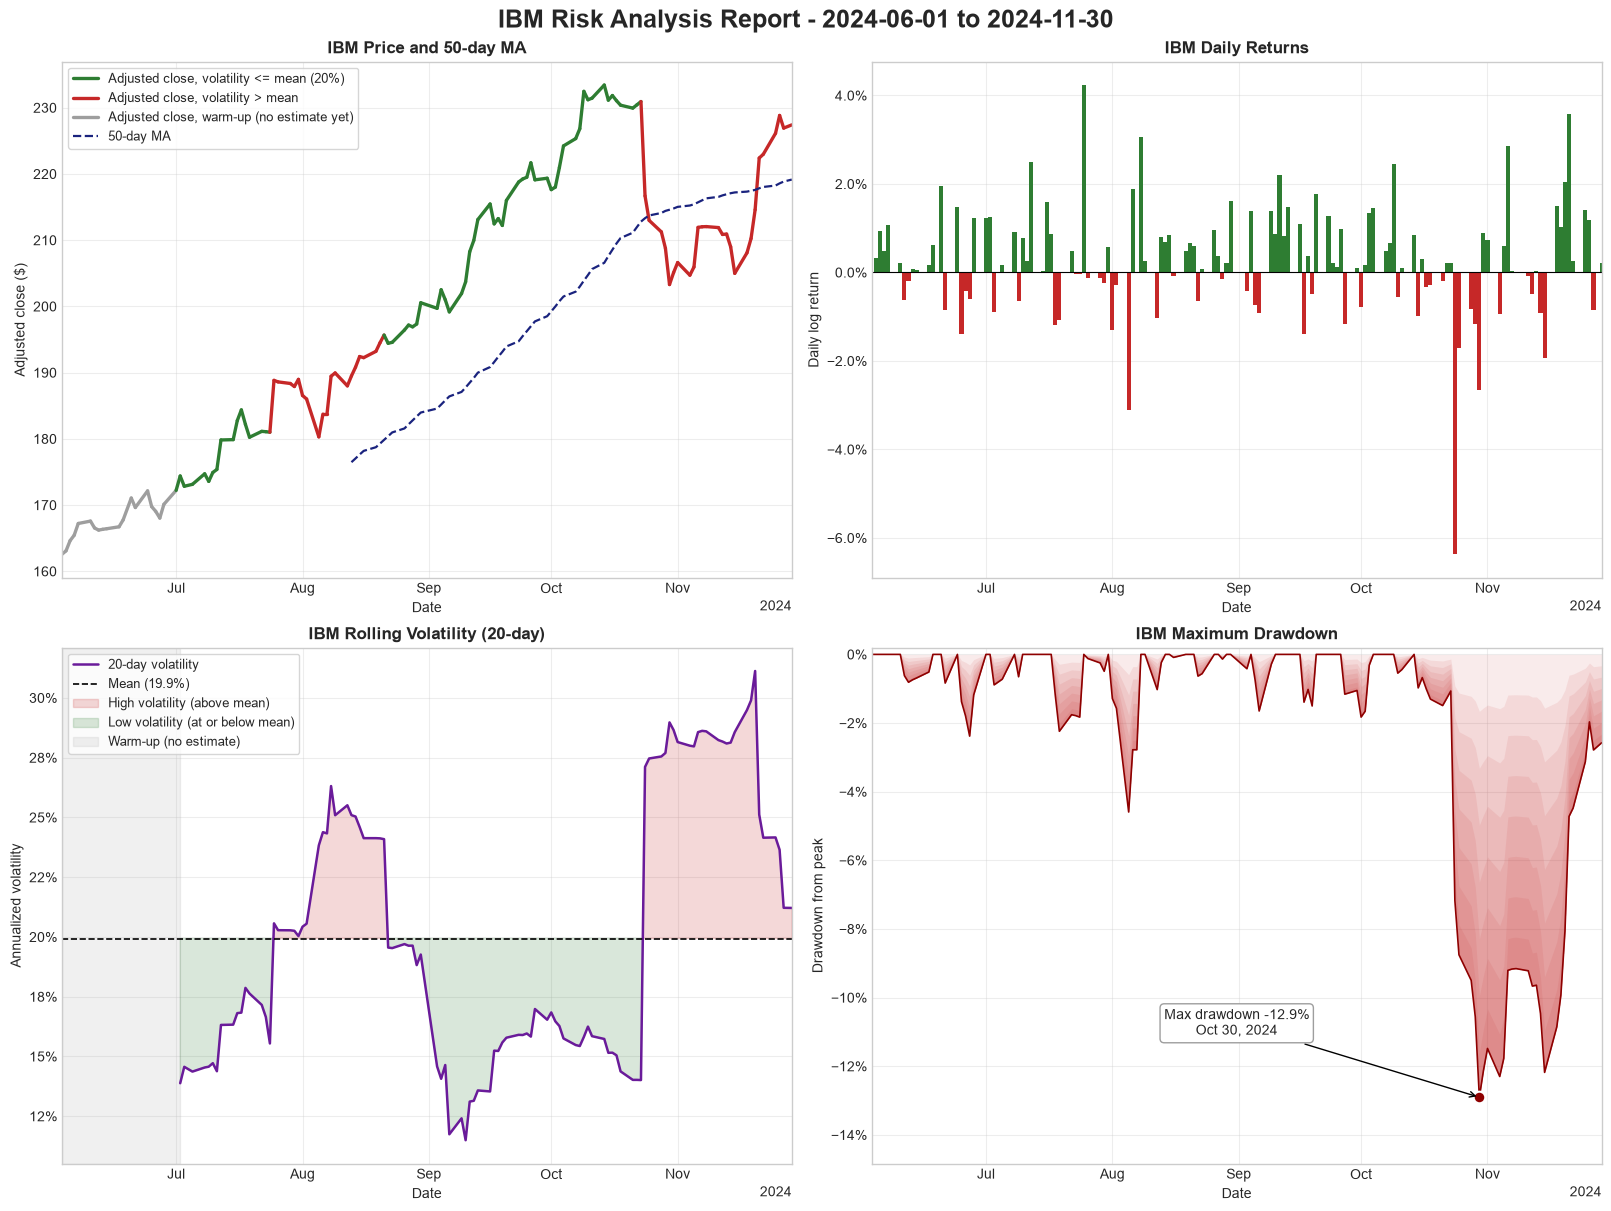

In [10]:
def format_date_axis(ax):
    """Compact date labels ('Jul', 'Aug', ... with the year shown once)."""
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


def plot_price(ax, data, threshold):
    """Adjusted close coloured by rolling volatility versus its mean (red above, green at or below,
    gray before an estimate exists), with the 50-day moving average."""
    x = mdates.date2num(data.index)
    y = data["adj_close"].to_numpy()
    points = np.column_stack([x, y])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    vol = data["volatility"].to_numpy()[1:]  # each segment takes the volatility at its end date
    colors = np.where(np.isnan(vol), GREY, np.where(vol > threshold, RED, GREEN))
    ax.add_collection(LineCollection(segments, colors=colors, linewidth=2.4, capstyle="round"))

    handles = [Line2D([], [], color=GREEN, linewidth=2.4, label=f"Adjusted close, volatility <= mean ({fmt(threshold, '.0%')})"),
               Line2D([], [], color=RED, linewidth=2.4, label="Adjusted close, volatility > mean"),
               Line2D([], [], color=GREY, linewidth=2.4, label="Adjusted close, warm-up (no estimate yet)")]
    if data["ma_50"].notna().any():
        ax.plot(data.index, data["ma_50"], color=NAVY, linestyle="--", linewidth=1.6)
        handles.append(Line2D([], [], color=NAVY, linestyle="--", linewidth=1.6, label="50-day MA"))
    else:
        handles.append(Line2D([], [], color=NAVY, linestyle="--", linewidth=1.6,
                              label=f"50-day MA unavailable (< {MA_WINDOW} prices)"))

    low, high = np.nanmin([y.min(), data["ma_50"].min()]), np.nanmax([y.max(), data["ma_50"].max()])
    pad = 0.05 * (high - low)
    ax.set_ylim(low - pad, high + pad)
    ax.legend(handles=handles, loc="upper left", frameon=True, fontsize=9)
    ax.set(title=f"{ticker} Price and 50-day MA", ylabel="Adjusted close ($)")


def plot_returns(ax, data):
    """Daily log returns as bars: green up days, red down days."""
    returns = data["log_return"].dropna()
    ax.bar(returns.index, returns, width=1.0, linewidth=0, color=np.where(returns > 0, GREEN, RED))
    ax.axhline(0, color="black", linewidth=0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
    ax.set(title=f"{ticker} Daily Returns", ylabel="Daily log return")


def plot_volatility(ax, data, threshold):
    """Rolling volatility with its mean; above-mean regimes shaded red, below-mean green, warm-up gray."""
    vol = data["volatility"]
    ax.plot(vol.index, vol, color=PURPLE, linewidth=1.8, label="20-day volatility")
    ax.axhline(threshold, color="black", linestyle="--", linewidth=1.2, label=f"Mean ({fmt(threshold, '.1%')})")
    ax.fill_between(vol.index, vol, threshold, where=vol > threshold, interpolate=True,
                    color=RED, alpha=0.18, label="High volatility (above mean)")
    ax.fill_between(vol.index, vol, threshold, where=vol <= threshold, interpolate=True,
                    color=GREEN, alpha=0.18, label="Low volatility (at or below mean)")
    first_estimate = vol.first_valid_index()
    if first_estimate is not None and first_estimate > vol.index[0]:
        ax.axvspan(vol.index[0], first_estimate, color=GREY, alpha=0.15, label="Warm-up (no estimate)")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.legend(loc="upper left", frameon=True, fontsize=9)
    ax.set(title=f"{ticker} Rolling Volatility (20-day)", ylabel="Annualized volatility")


def plot_drawdown(ax, data):
    """Drawdown area in layered transparent red fills (deeper = darker), worst point marked."""
    dd = data["drawdown"]
    worst_day, worst = dd.idxmin(), dd.min()
    # Each layer fills the band between the curve and a fraction of it, so layers pile up near the
    # curve: the deeper the drawdown, the darker the fill
    for fraction in np.linspace(0.0, 0.9, 8):
        ax.fill_between(dd.index, dd, dd * fraction, color=RED, alpha=0.09, linewidth=0)
    ax.plot(dd.index, dd, color=DARK_RED, linewidth=1.2)

    ax.scatter([worst_day], [worst], s=70, color=DARK_RED, edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"Max drawdown {worst:.1%}\n{worst_day:%b %d, %Y}", xy=(worst_day, worst),
                xytext=(0.5, 0.25), textcoords="axes fraction", ha="center", fontsize=10,
                arrowprops=dict(arrowstyle="->", color="black"),
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=GREY))
    bottom = min(worst, -0.005)  # keep a visible scale if the stock never fell from a peak
    ax.set_ylim(bottom * 1.15, 0.002)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown from peak")


fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
plot_price(axes[0, 0], report, mean_volatility)
plot_returns(axes[0, 1], report)
plot_volatility(axes[1, 0], report, mean_volatility)
plot_drawdown(axes[1, 1], report)
for ax in axes.flat:
    ax.set_xlim(report.index[0], report.index[-1])  # same date range on all four panels
    ax.grid(True, alpha=0.35)
    ax.set_xlabel("Date")
    format_date_axis(ax)
    ax.title.set_fontweight("bold")
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
plt.show()

## Summary statistics

- **Total return**: `last adjusted close / first adjusted close - 1`.
- **Annualized return**: `exp(sum of log returns × 252 / n) - 1`, the total return compounded to a 252-day year.
- **Annualized volatility**: the standard deviation of all daily log returns × √252. This whole-period figure differs
  from the *mean rolling* volatility used in the portfolio summary.
- **Sharpe ratio**: the assignment's approximation, `(mean log return × 252 − 2%) / (std × √252)`.
- **Day statistics** use daily log returns. *Positive days* is the share of returns above zero, counting zero days in
  the total.

Over a short window, annualized figures extrapolate a few months to a full year. Read them as rates, not forecasts.

In [11]:
log_returns = report["log_return"].dropna()
up_days, down_days = log_returns[log_returns > 0], log_returns[log_returns < 0]
n = len(log_returns)

stats = {
    "total_return": report["adj_close"].iloc[-1] / report["adj_close"].iloc[0] - 1,
    "annualized_return": np.exp(log_returns.sum() * TRADING_DAYS / n) - 1 if n else np.nan,
    "annualized_volatility": log_returns.std() * np.sqrt(TRADING_DAYS) if n > 1 else np.nan,
    "sharpe_ratio": sharpe_ratio,
    "max_drawdown": report["drawdown"].min(),
    "best_day": log_returns.max(),
    "worst_day": log_returns.min(),
    "positive_days": (log_returns > 0).mean() if n else np.nan,
    "avg_up_day": up_days.mean() if len(up_days) else np.nan,
    "avg_down_day": down_days.mean() if len(down_days) else np.nan,
}

summary_table = pd.DataFrame({
    "Metric": ["Total Return", "Annualized Return", "Annualized Volatility", "Sharpe Ratio", "Maximum Drawdown",
               "Best Day", "Worst Day", "Positive Days", "Average Up Day", "Average Down Day"],
    "Value": [fmt(stats["total_return"], "+.2%"), fmt(stats["annualized_return"], "+.2%"),
              fmt(stats["annualized_volatility"], ".2%"), fmt(stats["sharpe_ratio"], ".2f"),
              fmt(stats["max_drawdown"], ".2%"), fmt(stats["best_day"], "+.2%"), fmt(stats["worst_day"], "+.2%"),
              fmt(stats["positive_days"], ".1%"), fmt(stats["avg_up_day"], "+.2%"), fmt(stats["avg_down_day"], "+.2%")],
}).set_index("Metric")
summary_table

,Value
Metric,
Total Return,+39.88%
Annualized Return,+96.73%
Annualized Volatility,20.42%
Sharpe Ratio,3.22
Maximum Drawdown,-12.90%
Best Day,+4.24%
Worst Day,-6.37%
Positive Days,63.2%
Average Up Day,+0.95%


## Export results for the batch run

`03_run_all_stocks.py` reads these values back from each executed report with `scrapbook`, so the
portfolio summary uses exactly the numbers shown above. Values are fractions (not percentages); undefined
values are stored as `None`.

In [12]:
def as_number(value):
    """Plain float for export, or None if the value is undefined."""
    return None if pd.isna(value) else float(value)


results = {
    "ticker": ticker,
    "start_date": start_date,
    "end_date": end_date,
    "first_day": f"{first_day:%Y-%m-%d}",
    "last_day": f"{last_day:%Y-%m-%d}",
    "trading_days": len(report),
    "avg_daily_return": as_number(log_returns.mean()),
    "avg_volatility": as_number(mean_volatility),
    **{name: as_number(value) for name, value in stats.items()},
}
sb.glue("results", results)
pd.Series(results, name=ticker).to_frame()

,IBM
ticker,IBM
start_date,2024-06-01
end_date,2024-11-30
first_day,2024-06-03
last_day,2024-11-29
trading_days,126
avg_daily_return,0.002685
avg_volatility,0.199332
total_return,0.398844
annualized_return,0.9673
